# SmartPantry AI: Image Recognition

## 1. Introduction

SmartPantry AI uses a pretrained OpenAI vision-capable model to identify food items from photographs.

The image recognition feature is designed to help users identify food items without manually entering their names.

### Objectives

- Identify common food items from images.
- Evaluate recognition performance under different image conditions.
- Test images containing shadows, different lighting, angles, and food preparations.
- Document expected and actual recognition results.
- Identify limitations and opportunities for improvement.

### Model

- **AI Model:** OpenAI GPT-4.1 mini
- **Approach:** Pretrained vision model accessed through the OpenAI API
- **Programming Language:** Python
- **Evaluation Dataset:** 25 food images

## 2. Image Recognition Technology

SmartPantry AI uses OpenAI's pretrained GPT-4.1 mini model, which supports image understanding.

The model analyzes an uploaded food photograph and generates a text response identifying the main food item.

### Technologies Used

- **Python:** Implements the image recognition functionality.
- **OpenAI API:** Provides access to the pretrained vision-capable model.
- **GPT-4.1 mini:** Analyzes images and identifies food items.
- **Base64:** Encodes image bytes into a format suitable for transmission.
- **python-dotenv:** Loads the API key from the project's `.env` file.

### Recognition Pipeline

1. The application receives an image file path.
2. Python verifies that the image file exists.
3. The image is read and encoded using Base64.
4. The encoded image and identification instructions are sent to the OpenAI API.
5. The pretrained model analyzes the image.
6. The model returns the identified food name.
7. SmartPantry receives the prediction for further processing.

### Important Distinction

This project uses a pretrained AI model for inference.

We are not training or fine-tuning the model. Instead, we evaluate its ability to recognize food items under different photographic conditions.

## 3. Python Environment and Imports

This section prepares the notebook environment and imports the libraries needed to inspect images and evaluate recognition results.

The notebook will reuse the existing image recognition module rather than duplicate its implementation.

In [1]:
from pathlib import Path

project_root = Path.cwd()
print("Current working directory:", project_root)

Current working directory: c:\Users\Samir\GitHub\smartpantry-ai\notebooks


In [2]:
project_root = Path.cwd().parent

print("Project root:", project_root)
print("Modules folder exists:", (project_root / "modules").is_dir())
print("Test images folder exists:", (project_root / "test_images").is_dir())

Project root: c:\Users\Samir\GitHub\smartpantry-ai
Modules folder exists: True
Test images folder exists: True


In [3]:
import sys

sys.path.insert(0, str(project_root))

from modules.image_recognition import recognize_food

print("Image recognition module imported successfully!")

Image recognition module imported successfully!


## 4. Image Dataset Exploration

This section examines the food images used to evaluate SmartPantry's recognition capabilities.

The evaluation dataset contains:
- 5 original baseline images.
- 20 challenging images featuring different lighting, shadows, angles, and food preparations.

These images are used for evaluation, not model training.

In [4]:
baseline_folder = project_root / "test_images"
challenging_folder = baseline_folder / "challenging"

baseline_images = sorted(baseline_folder.glob("*.jpg"))
challenging_images = sorted(challenging_folder.glob("*.jpg"))

print("Baseline images:", len(baseline_images))
print("Challenging images:", len(challenging_images))
print("Total images:", len(baseline_images) + len(challenging_images))

Baseline images: 5
Challenging images: 20
Total images: 25


### 4.1 Visual Inspection of Test Images

Before evaluating recognition results, we visually inspect sample images to verify that the dataset contains the intended food items.

This step does not use the OpenAI API.

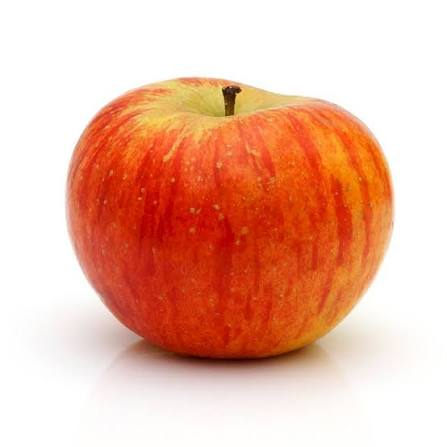

In [5]:
from IPython.display import display, Image

sample_image = baseline_folder / "Apple.jpg"

display(Image(filename=str(sample_image), width=300))

### 4.2 Baseline vs. Challenging Images

The baseline dataset contains the original food photographs used during initial testing.

The challenging dataset contains additional photographs with variations in lighting, shadows, viewing angles, backgrounds, and food presentation.

Comparing these datasets helps evaluate how consistently the pretrained model identifies food under different conditions.

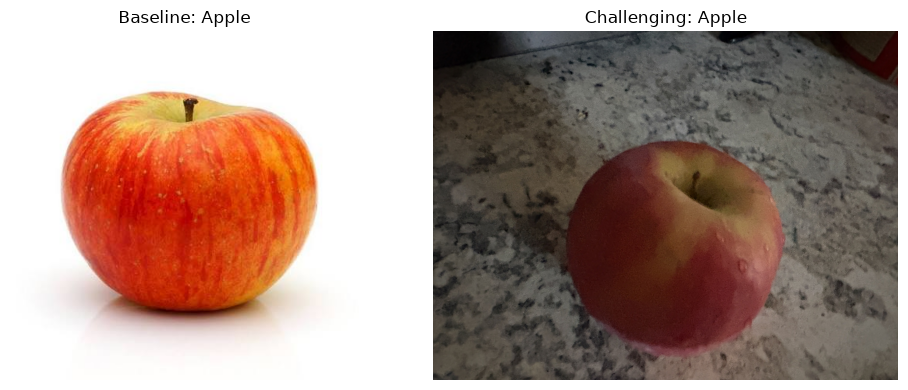

In [7]:
from matplotlib import pyplot as plt
from PIL import Image as PILImage

baseline_apple = baseline_folder / "Apple.jpg"
challenging_apple = challenging_folder / "apple_challenge_1.jpg"

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(PILImage.open(baseline_apple))
axes[0].set_title("Baseline: Apple")
axes[0].axis("off")

axes[1].imshow(PILImage.open(challenging_apple))
axes[1].set_title("Challenging: Apple")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 5. Image Recognition Evaluation

### 5.1 Evaluation Methodology

SmartPantry AI was evaluated using 25 food photographs divided into two groups:

- **Baseline dataset:** 5 original food photographs.
- **Challenging dataset:** 20 additional photographs featuring variations in lighting, shadows, angles, backgrounds, and food preparation.

Each image was submitted to the pretrained GPT-4.1 mini model using the `recognize_food()` function.

The model's response was compared against the expected food category.

### Evaluation Criteria

- **PASS:** The model correctly identifies the food category.
- **FAIL:** The model identifies an incorrect food category or returns an unusable prediction.
- **Name variation:** A correct food identification with different wording is recorded separately.

For example, "Banana slices" is considered a correct identification of banana, even though it is not an exact text match.

### Accuracy Formula

Accuracy (%) = (Correct Identifications / Total Images Tested) × 100

### Important Limitations

The evaluation measures performance on a small, selected dataset. Results do not establish the model's accuracy on unfamiliar foods or all real-world photographic conditions.

The model was not trained or fine-tuned using these images.

### 5.2 Baseline Image Recognition Results

The baseline evaluation consists of five original food photographs.

The expected food categories and actual model predictions were recorded during the initial image recognition testing.

These results are stored in Python so they can be analyzed and visualized without repeating paid API requests.

In [8]:
baseline_results = [
    {"image": "Apple.jpg", "expected": "Apple", "actual": "Apple"},
    {"image": "Bananas.jpg", "expected": "Banana", "actual": "Bananas"},
    {"image": "milk.jpg", "expected": "Milk", "actual": "Milk"},
    {"image": "spinach.jpg", "expected": "Spinach", "actual": "Spinach"},
    {"image": "tomato.jpg", "expected": "Tomato", "actual": "Tomato"},
]

print("Baseline records:", len(baseline_results))

Baseline records: 5


In [9]:
import pandas as pd

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df)

,image,expected,actual
0,Apple.jpg,Apple,Apple
1,Bananas.jpg,Banana,Bananas
2,milk.jpg,Milk,Milk
3,spinach.jpg,Spinach,Spinach
4,tomato.jpg,Tomato,Tomato


### 5.3 Challenging Image Recognition Results

The challenging dataset contains 20 photographs representing variations in lighting, shadows, angles, backgrounds, and food preparation.

The following records preserve the model's actual responses from our manual testing sessions.

These results will be evaluated separately from the baseline dataset.

In [10]:
challenging_results = [
    {"image": "apple_challenge_1.jpg", "expected": "Apple", "actual": "Apple"},
    {"image": "apple_challenge_2.jpg", "expected": "Apple", "actual": "Apple"},
    {"image": "apple_challenge_3.jpg", "expected": "Apple", "actual": "Apple"},
    {"image": "apple_challenge_4.jpg", "expected": "Apple", "actual": "Apple"},

    {"image": "banana_challenge_1.jpg", "expected": "Banana", "actual": "Banana"},
    {"image": "banana_challenge_2.jpg", "expected": "Banana", "actual": "Banana"},
    {"image": "banana_challenge_3.jpg", "expected": "Banana", "actual": "Banana slices"},
    {"image": "banana_challenge_4.jpg", "expected": "Banana", "actual": "Banana"},
]

print("Challenging records entered:", len(challenging_results))

Challenging records entered: 8


In [11]:
challenging_results.extend([
    {"image": "milk_challenge_1.jpg", "expected": "Milk", "actual": "Milk"},
    {"image": "milk_challenge_2.jpg", "expected": "Milk", "actual": "Milk"},
    {"image": "milk_challenge_3.jpg", "expected": "Milk", "actual": "Milk"},
    {"image": "milk_challenge_4.jpg", "expected": "Milk", "actual": "Milk"},

    {"image": "spinach_challenge_1.jpg", "expected": "Spinach", "actual": "Spinach"},
    {"image": "spinach_challenge_2.jpg", "expected": "Spinach", "actual": "Spinach"},

    {"image": "tomato_challenge_1.jpg", "expected": "Tomato", "actual": "Tomato"},
    {"image": "tomato_challenge_2.jpg", "expected": "Tomato", "actual": "Tomato"},

    {"image": "matchstickcarrots_challenge1.jpg", "expected": "Carrot", "actual": "Carrots"},
    {"image": "matchstickcarrots_challenge2.jpg", "expected": "Carrot", "actual": "Carrots"},
    {"image": "matchstickcarrots_challenge3.jpg", "expected": "Carrot", "actual": "Carrots"},
    {"image": "matchstickcarrots_challenge4.jpg", "expected": "Carrot", "actual": "Carrots"},
])

print("Total challenging records:", len(challenging_results))

Total challenging records: 20


In [12]:
challenging_df = pd.DataFrame(challenging_results)

print("Total records:", len(challenging_df))
print("Duplicate filenames:", challenging_df["image"].duplicated().sum())
print("Missing values:", challenging_df.isnull().sum().sum())

display(challenging_df)

Total records: 20
Duplicate filenames: 0
Missing values: 0


,image,expected,actual
0,apple_challenge_1.jpg,Apple,Apple
1,apple_challenge_2.jpg,Apple,Apple
2,apple_challenge_3.jpg,Apple,Apple
3,apple_challenge_4.jpg,Apple,Apple
4,banana_challenge_1.jpg,Banana,Banana
5,banana_challenge_2.jpg,Banana,Banana
6,banana_challenge_3.jpg,Banana,Banana slices
7,banana_challenge_4.jpg,Banana,Banana
8,milk_challenge_1.jpg,Milk,Milk
9,milk_challenge_2.jpg,Milk,Milk


### 5.4 Food Category Normalization

The recognition model may return different descriptions for the same food.

To evaluate food identification accuracy fairly, equivalent names are mapped to a common food category.

This normalization is used for evaluation and does not modify the model's original predictions.

In [13]:
food_name_mapping = {
    "apple": "apple",
    "banana": "banana",
    "bananas": "banana",
    "banana slices": "banana",
    "milk": "milk",
    "spinach": "spinach",
    "tomato": "tomato",
    "carrot": "carrot",
    "carrots": "carrot",
}

def normalize_food_name(name):
    cleaned_name = name.strip().lower()
    return food_name_mapping.get(cleaned_name, cleaned_name)

In [14]:
print(normalize_food_name("Bananas"))
print(normalize_food_name("Banana slices"))
print(normalize_food_name("Carrots"))
print(normalize_food_name("Spinach"))

banana
banana
carrot
spinach


### 5.5 Recognition Accuracy Calculation

Two evaluation metrics are calculated:

1. **Food identification accuracy:** Measures whether the model identifies the correct food category after normalizing known name variations.
2. **Exact-name match rate:** Measures whether the predicted name exactly matches the expected name, ignoring capitalization and surrounding spaces.

These metrics help distinguish successful food identification from differences in the model's wording.

In [15]:
all_results_df = pd.concat(
    [baseline_df, challenging_df],
    ignore_index=True
)

all_results_df["food_correct"] = (
    all_results_df["expected"].apply(normalize_food_name)
    == all_results_df["actual"].apply(normalize_food_name)
)

all_results_df["exact_match"] = (
    all_results_df["expected"].str.strip().str.lower()
    == all_results_df["actual"].str.strip().str.lower()
)

display(all_results_df.head())

,image,expected,actual,food_correct,exact_match
0,Apple.jpg,Apple,Apple,True,True
1,Bananas.jpg,Banana,Bananas,True,False
2,milk.jpg,Milk,Milk,True,True
3,spinach.jpg,Spinach,Spinach,True,True
4,tomato.jpg,Tomato,Tomato,True,True


In [16]:
total_images = len(all_results_df)

correct_foods = all_results_df["food_correct"].sum()
exact_matches = all_results_df["exact_match"].sum()

food_accuracy = (correct_foods / total_images) * 100
exact_match_rate = (exact_matches / total_images) * 100

print(f"Total images tested: {total_images}")
print(f"Correct food identifications: {correct_foods}")
print(f"Food identification accuracy: {food_accuracy:.2f}%")
print(f"Exact-name matches: {exact_matches}")
print(f"Exact-name match rate: {exact_match_rate:.2f}%")

Total images tested: 25
Correct food identifications: 25
Food identification accuracy: 100.00%
Exact-name matches: 19
Exact-name match rate: 76.00%


### 5.6 Evaluation Results Visualization

The chart below compares food identification accuracy with exact-name matching.

The difference demonstrates that a model can correctly identify a food item while returning a different name or description.

These results represent performance on the 25 selected evaluation images and should not be interpreted as general model accuracy.

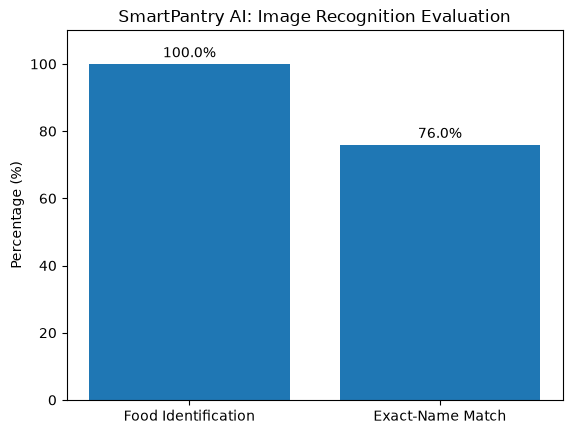

In [17]:
metrics = ["Food Identification", "Exact-Name Match"]
scores = [food_accuracy, exact_match_rate]

plt.bar(metrics, scores)

plt.title("SmartPantry AI: Image Recognition Evaluation")
plt.ylabel("Percentage (%)")
plt.ylim(0, 110)

for index, score in enumerate(scores):
    plt.text(index, score + 2, f"{score:.1f}%", ha="center")

plt.show()

In [18]:
print("Total images:", len(all_results_df))
print("Correct identifications:", all_results_df["food_correct"].sum())
print("Exact-name matches:", all_results_df["exact_match"].sum())
print("Duplicate filenames:", all_results_df["image"].duplicated().sum())

Total images: 25
Correct identifications: 25
Exact-name matches: 19
Duplicate filenames: 0
